<a href="https://colab.research.google.com/github/jainjay4405/Customer_churn_project/blob/main/customer_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
(df["TotalCharges"] == "").sum()

np.int64(0)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
pd.to_numeric(df["TotalCharges"],errors="coerce").isnull().sum()

np.int64(11)

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors = "coerce")

In [ ]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
df = df.dropna(subset = ["TotalCharges"])

In [ ]:
print("shapes :", df.shape)
print("missing total charges :",df["TotalCharges"].isnull().sum())

shapes : (7032, 21)
missing total charges : 0


In [ ]:
df.drop("customerID",axis = 1 , inplace=True)

In [ ]:
df.duplicated().sum()
df.nunique()

,0
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,72
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3


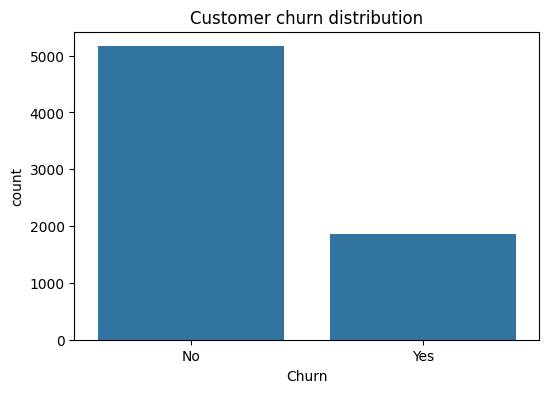

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize =(6,4))
sns.countplot(data=df, x= "Churn")
plt.title("Customer churn distribution")
plt.show()

In [ ]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.421502
Yes,26.578498


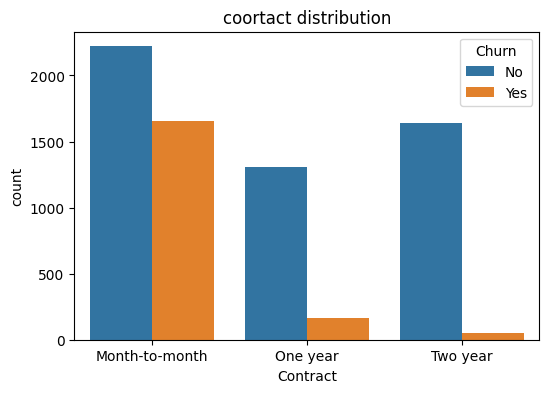

In [ ]:
plt.figure(figsize =(6,4))
sns.countplot(data = df, x= "Contract",hue = "Churn")
plt.title("coortact distribution")
plt.show()

In [ ]:
contract_churn = pd.crosstab(df["Contract"],df['Churn'],normalize="index") *100
print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


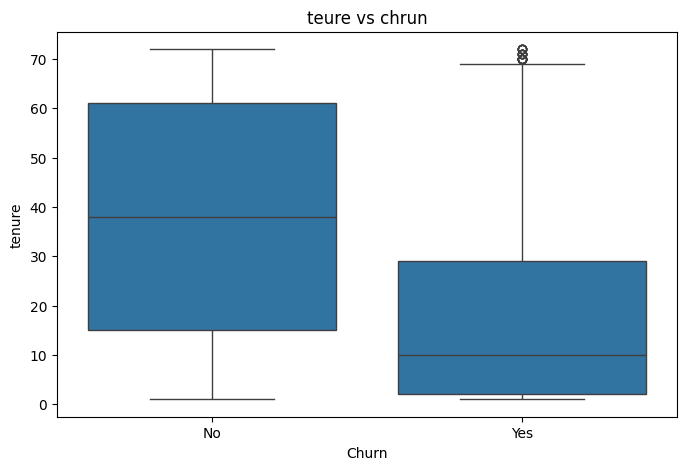

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data = df,
            x ="Churn",
            y ="tenure")
plt.title("teure vs chrun")
plt.show()

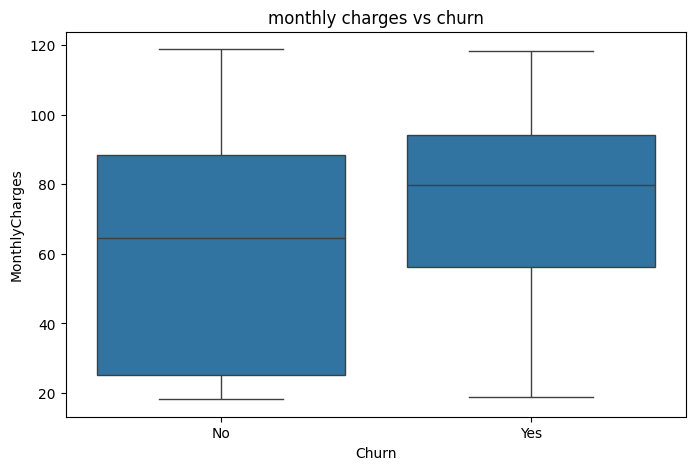

In [ ]:
plt.figure(figsize = (8,5))

sns.boxplot(data = df ,
            x = "Churn",
            y = "MonthlyCharges")
plt.title("monthly charges vs churn")
plt.show()

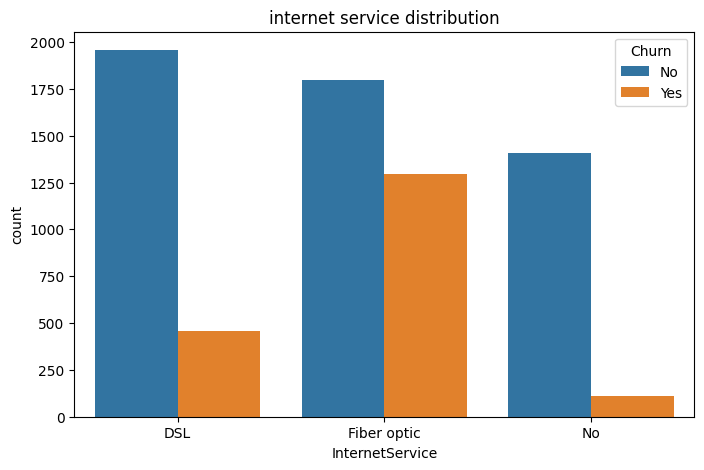

In [ ]:
plt.figure(figsize = (8,5))

sns.countplot(data = df,
              x ="InternetService",
              hue ="Churn")

plt.title("internet service distribution")
plt.show()

In [ ]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


In [ ]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)


Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


In [ ]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn)

Churn                 No        Yes
SeniorCitizen                      
0              76.349745  23.650255
1              58.318739  41.681261


In [ ]:
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation = df[numeric_cols].corr()

print(correlation)

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.015683        0.219874      0.102411
tenure               0.015683  1.000000        0.246862      0.825880
MonthlyCharges       0.219874  0.246862        1.000000      0.651065
TotalCharges         0.102411  0.825880        0.651065      1.000000


feature engineering

In [ ]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes" : 1
})

In [ ]:
df["Churn"].value_counts()

,count
Churn,
0,5163
1,1869


In [ ]:
df["AverageMonthlySpend"] = np.where(
    df["tenure"] >0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"])

In [ ]:
df[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "AverageMonthlySpend",
    "Churn"
]].head(10)


,tenure,MonthlyCharges,TotalCharges,AverageMonthlySpend,Churn
0,1,29.85,29.85,29.850000,0
1,34,56.95,1889.50,55.573529,0
2,2,53.85,108.15,54.075000,1
3,45,42.30,1840.75,40.905556,0
4,2,70.70,151.65,75.825000,1
5,8,99.65,820.50,102.562500,1
6,22,89.10,1949.40,88.609091,0
7,10,29.75,301.90,30.190000,0
8,28,104.80,3046.05,108.787500,1
9,62,56.15,3487.95,56.257258,0


In [ ]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [ ]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageMonthlySpend']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (5625, 20)
X_test: (1407, 20)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Before:", X_train.shape)
print("After:", X_train_processed.shape)
print("Test:", X_test_processed.shape)

Before: (5625, 20)
After: (5625, 46)
Test: (1407, 46)


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [ ]:
log_model.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
y_pred = log_model.predict(X_test_processed)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8038379530916845

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[917 116]
 [160 214]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train_processed, y_train)

tree_pred = tree_model.predict(X_test_processed)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Decision Tree Accuracy:",
      accuracy_score(y_test, tree_pred))

print("\nClassification Report:")
print(classification_report(y_test, tree_pred))

Decision Tree Accuracy: 0.7839374555792467

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1033
           1       0.59      0.64      0.61       374

    accuracy                           0.78      1407
   macro avg       0.73      0.74      0.73      1407
weighted avg       0.79      0.78      0.79      1407



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_model.fit(X_train_processed, y_train)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
rf_pred = rf_model.predict(X_test_processed)

In [ ]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.7896233120113717

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.63      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, tree_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, tree_pred),
        f1_score(y_test, rf_pred)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.803838,0.648485,0.572193,0.607955
1,Decision Tree,0.783937,0.586207,0.636364,0.610256
2,Random Forest,0.789623,0.630000,0.505348,0.560831


In [ ]:
log_prob = log_model.predict_proba(X_test_processed)[:, 1]
tree_prob = tree_model.predict_proba(X_test_processed)[:, 1]
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]
from sklearn.metrics import roc_auc_score

print("Logistic Regression:",
      roc_auc_score(y_test, log_prob))

print("Decision Tree:",
      roc_auc_score(y_test, tree_prob))

print("Random Forest:",
      roc_auc_score(y_test, rf_prob))

Logistic Regression: 0.8359911684466094
Decision Tree: 0.8226739520942584
Random Forest: 0.817457071713663


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000, random_state=42),
             n_jobs=-1, param_grid={'C': [0.01, 0.1, 1, 10, 100]},
             scoring='roc_auc')

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

Best Parameters:
{'C': 100}

Best Cross-Validation ROC-AUC:
0.8459509907925531


In [ ]:
best_log_model = grid_search.best_estimator_

tuned_pred = best_log_model.predict(X_test_processed)
tuned_prob = best_log_model.predict_proba(
    X_test_processed
)[:, 1]

In [ ]:
print("Test Accuracy:",
      accuracy_score(y_test, tuned_pred))

print("\nClassification Report:")
print(classification_report(y_test, tuned_pred))

print("\nTest ROC-AUC:",
      roc_auc_score(y_test, tuned_prob))

Test Accuracy: 0.798862828713575

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1033
           1       0.64      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.73      0.73      1407
weighted avg       0.79      0.80      0.80      1407


Test ROC-AUC: 0.8348263973370744


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print(len(feature_names))
print(feature_names)

46
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'num__AverageMonthlySpend' 'cat__gender_Female'
 'cat__gender_Male' 'cat__Partner_No' 'cat__Partner_Yes'
 'cat__Dependents_No' 'cat__Dependents_Yes' 'cat__PhoneService_No'
 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__StreamingMovies_No internet service'
 'cat__StreamingMov

In [ ]:
coefficients = log_model.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print(coef_df.sort_values("Coefficient", ascending=False).head(10))

                                Feature  Coefficient
3                     num__TotalCharges     0.637689
37         cat__Contract_Month-to-month     0.617715
17     cat__InternetService_Fiber optic     0.570021
33                 cat__StreamingTV_Yes     0.184570
44  cat__PaymentMethod_Electronic check     0.183447
36             cat__StreamingMovies_Yes     0.169554
19               cat__OnlineSecurity_No     0.169189
4              num__AverageMonthlySpend     0.163105
28                  cat__TechSupport_No     0.147583
15               cat__MultipleLines_Yes     0.084220


In [ ]:
rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(rf_importance_df.head(15))

                                Feature  Importance
3                     num__TotalCharges    0.138805
1                           num__tenure    0.124014
4              num__AverageMonthlySpend    0.118518
2                   num__MonthlyCharges    0.109975
37         cat__Contract_Month-to-month    0.048558
19               cat__OnlineSecurity_No    0.028108
44  cat__PaymentMethod_Electronic check    0.027952
28                  cat__TechSupport_No    0.025211
17     cat__InternetService_Fiber optic    0.019702
39               cat__Contract_Two year    0.019170
6                      cat__gender_Male    0.016292
0                    num__SeniorCitizen    0.016272
22                 cat__OnlineBackup_No    0.016185
5                    cat__gender_Female    0.015434
25             cat__DeviceProtection_No    0.014588


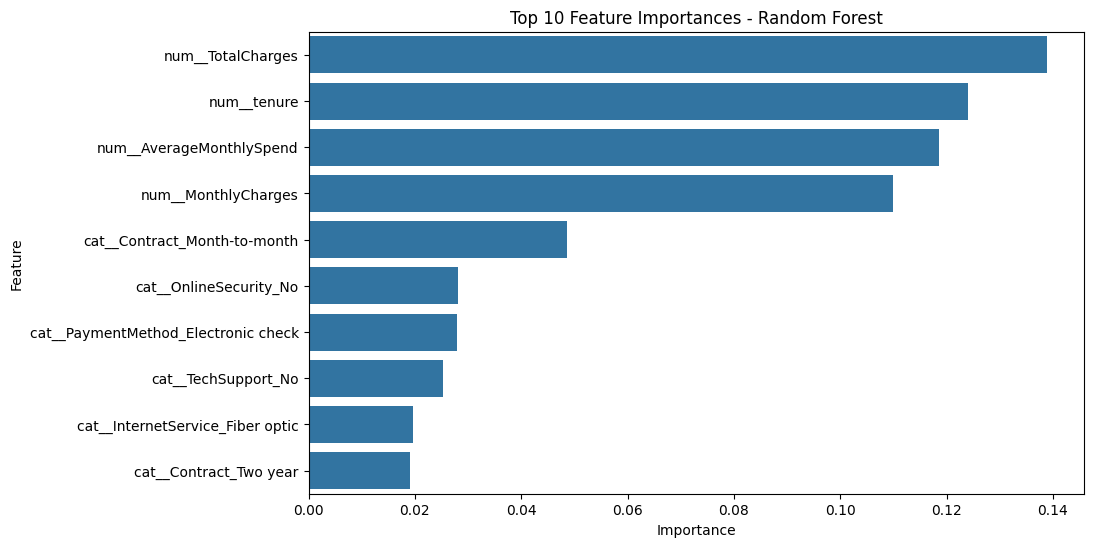

In [ ]:
top_features = rf_importance_df.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

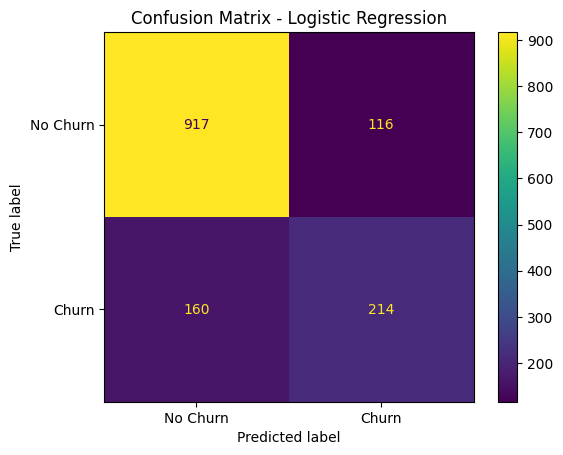

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [ ]:
import joblib

joblib.dump(final_model, "customer_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import os

print(os.path.exists("customer_churn_model.pkl"))

True


In [ ]:
print(os.path.getsize("customer_churn_model.pkl"), "bytes")

7729 bytes


In [ ]:
from google.colab import files

files.download("customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>